In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler,
                                   MinMaxScaler, RobustScaler, PowerTransformer, FunctionTransformer)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from imblearn.over_sampling import RandomOverSampler, SMOTE

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.4.6


---
# Task 1: Dataset Loading and Exploration
**Why:** Before cleaning anything we must understand the data: its size, columns, data types and basic statistics. The original dataframe is stored in `df_raw` and never modified; all work is done on `df`.

In [ ]:
df_raw = pd.read_csv("hotel_bookings.csv")
df = df_raw.copy()
print("Dataset loaded successfully")
url = 

Dataset loaded successfully


In [ ]:
print("First five records")
display(df.head())
print("Last five records")
display(df.tail())

First five records
Last five records


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,2015-07-03


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.000,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.000,NaN,0,Transient,96.140,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.000,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.000,NaN,0,Transient,225.430,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.000,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.000,NaN,0,Transient,157.710,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.000,NaN,0,Transient,104.400,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,0.000,0,HB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.000,NaN,0,Transient,151.200,0,2,Check-Out,2017-09-07


In [ ]:
rows, cols = df.shape
print(f"Number of rows    : {rows:,}")
print(f"Number of columns : {cols}")

Number of rows    : 119,390
Number of columns : 32


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [ ]:
print("Statistical summary - numerical attributes")
display(df.describe().T)
print("Statistical summary - categorical attributes")
display(df.describe(include=["object", "string"]).T)

Statistical summary - numerical attributes
Statistical summary - categorical attributes


,count,mean,std,min,25%,50%,75%,max
is_canceled,"119,390.000",0.370,0.483,0.000,0.000,0.000,1.000,1.000
lead_time,"119,390.000",104.011,106.863,0.000,18.000,69.000,160.000,737.000
arrival_date_year,"119,390.000","2,016.157",0.707,"2,015.000","2,016.000","2,016.000","2,017.000","2,017.000"
arrival_date_week_number,"119,390.000",27.165,13.605,1.000,16.000,28.000,38.000,53.000
arrival_date_day_of_month,"119,390.000",15.798,8.781,1.000,8.000,16.000,23.000,31.000
stays_in_weekend_nights,"119,390.000",0.928,0.999,0.000,0.000,1.000,2.000,19.000
stays_in_week_nights,"119,390.000",2.500,1.908,0.000,1.000,2.000,3.000,50.000
adults,"119,390.000",1.856,0.579,0.000,2.000,2.000,2.000,55.000
children,"119,386.000",0.104,0.399,0.000,0.000,0.000,0.000,10.000
babies,"119,390.000",0.008,0.097,0.000,0.000,0.000,0.000,10.000


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


---
# Task 2: Data Type Identification


In [ ]:
TARGET = "is_canceled"
LEAKAGE_COLS = ["reservation_status", "reservation_status_date"]
date_related   = ["arrival_date_year", "arrival_date_month", "arrival_date_week_number",
                  "arrival_date_day_of_month", "reservation_status_date"]
id_like_cols   = ["agent", "company"]
binary_cols    = ["is_canceled", "is_repeated_guest"]
categorical_cols = [c for c in df.select_dtypes(include=["object", "string"]).columns
                    if c not in date_related] + id_like_cols
numerical_cols = [c for c in df.columns
                  if c not in categorical_cols + date_related + binary_cols]

print("NUMERICAL  :", numerical_cols, "\n")
print("CATEGORICAL:", categorical_cols, "\n")
print("BINARY FLAG:", binary_cols, "\n")
print("DATE-RELATED:", date_related)

NUMERICAL  : ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests'] 

CATEGORICAL: ['hotel', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'agent', 'company'] 

BINARY FLAG: ['is_canceled', 'is_repeated_guest'] 

DATE-RELATED: ['arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'reservation_status_date']


In [ ]:

type_issues = pd.DataFrame([
    ("reservation_status_date", "str/object", "text, should be a date",              "convert to datetime64"),
    ("arrival_date_month",      "str/object", "month names have a natural order",    "ordered categorical (Jan < ... < Dec)"),
    ("agent",                   "float64",    "ID number, arithmetic is meaningless", "categorical (string ID)"),
    ("company",                 "float64",    "ID number, arithmetic is meaningless", "categorical (string ID)"),
    ("children",                "float64",    "a count of people; float only because of NaN", "integer (after imputation, Task 3/16)"),
    ("is_canceled / is_repeated_guest", "int64", "binary flags",                     "int8"),
], columns=["column", "current dtype", "problem", "conversion"])
display(type_issues)

,column,current dtype,problem,conversion
0,reservation_status_date,str/object,"text, should be a date",convert to datetime64
1,arrival_date_month,str/object,month names have a natural order,ordered categorical (Jan < ... < Dec)
2,agent,float64,"ID number, arithmetic is meaningless",categorical (string ID)
3,company,float64,"ID number, arithmetic is meaningless",categorical (string ID)
4,children,float64,a count of people; float only because of NaN,"integer (after imputation, Task 3/16)"
5,is_canceled / is_repeated_guest,int64,binary flags,int8


In [ ]:
MONTHS = ["January","February","March","April","May","June","July",
          "August","September","October","November","December"]

# 1) dates
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])
# 2) month -> ordered categorical
df["arrival_date_month"] = pd.Categorical(df["arrival_date_month"], categories=MONTHS, ordered=True)
# 3) numeric IDs -> string categories (NaN stays NaN)
for c in id_like_cols:
    df[c] = df[c].map(lambda v: str(int(v)) if pd.notna(v) else np.nan)
# 4) binary flags -> int8
for c in binary_cols:
    df[c] = df[c].astype("int8")

print("Data types after conversion")
display(pd.DataFrame({"before": df_raw.dtypes.astype(str), "after": df.dtypes.astype(str)}))

Data types after conversion


,before,after
hotel,str,str
is_canceled,int64,int8
lead_time,int64,int64
arrival_date_year,int64,int64
arrival_date_month,str,category
arrival_date_week_number,int64,int64
arrival_date_day_of_month,int64,int64
stays_in_weekend_nights,int64,int64
stays_in_week_nights,int64,int64
adults,int64,int64


---
# Task 3: Missing Value Analysis


In [ ]:
missing = df.isna().sum().rename("missing_count").to_frame()
missing["missing_%"] = (missing["missing_count"] / len(df) * 100).round(3)
missing = missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)
print("Missing values per column")
display(missing)

Missing values per column


,missing_count,missing_%
company,112593,94.307
agent,16340,13.686
country,488,0.409
children,4,0.003


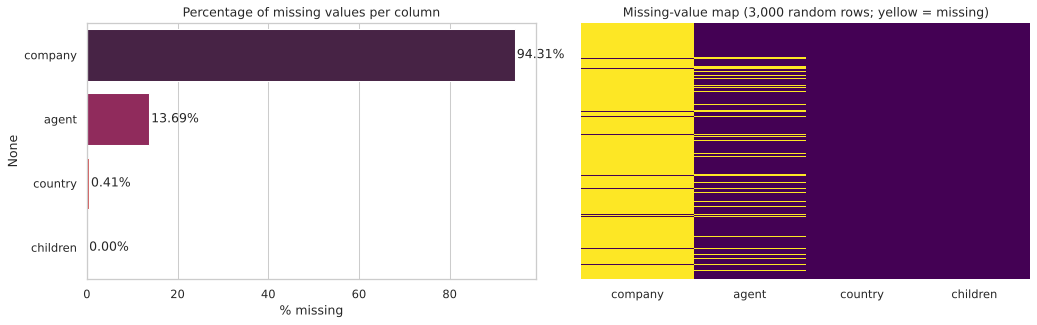

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=missing["missing_%"], y=missing.index, ax=ax[0], palette="rocket")
ax[0].set_title("Percentage of missing values per column"); ax[0].set_xlabel("% missing")
for i, v in enumerate(missing["missing_%"]):
    ax[0].text(v + 0.5, i, f"{v:.2f}%", va="center")

sample = df[missing.index].sample(3000, random_state=RANDOM_STATE).isna()
sns.heatmap(sample, cbar=False, yticklabels=False, cmap="viridis", ax=ax[1])
ax[1].set_title("Missing-value map (3,000 random rows; yellow = missing)")
plt.tight_layout(); plt.show()

### Comparing mean, median and mode imputation


In [ ]:
def summarize(s):
    return pd.Series({"non-null count": s.count(), "mean": s.mean(), "median": s.median(),
                      "std": s.std(), "skew": s.skew(), "distinct values": s.nunique()})

ch, ag = df_raw["children"], df_raw["agent"]

children_cmp = pd.DataFrame({
    "original (NaN ignored)": summarize(ch),
    "mean imputed":   summarize(ch.fillna(ch.mean())),
    "median imputed": summarize(ch.fillna(ch.median())),
    "mode imputed":   summarize(ch.fillna(ch.mode()[0])),
})
agent_cmp = pd.DataFrame({
    "original (NaN ignored)": summarize(ag),
    "mean imputed":   summarize(ag.fillna(ag.mean())),
    "median imputed": summarize(ag.fillna(ag.median())),
    "mode imputed":   summarize(ag.fillna(ag.mode()[0])),
    "constant 0 ('no agent')": summarize(ag.fillna(0)),
})
print("children  (only 4 missing):"); display(children_cmp)
print("agent     (16,340 missing):"); display(agent_cmp)
print("Value created by MEAN imputation in children:", round(ch.mean(), 4), "-> a fractional number of children!")

children  (only 4 missing):
agent     (16,340 missing):
Value created by MEAN imputation in children: 0.1039 -> a fractional number of children!


,original (NaN ignored),mean imputed,median imputed,mode imputed
non-null count,"119,386.000","119,390.000","119,390.000","119,390.000"
mean,0.104,0.104,0.104,0.104
median,0.000,0.000,0.000,0.000
std,0.399,0.399,0.399,0.399
skew,4.113,4.113,4.113,4.113
distinct values,5.000,6.000,5.000,5.000


,original (NaN ignored),mean imputed,median imputed,mode imputed,constant 0 ('no agent')
non-null count,"103,050.000","119,390.000","119,390.000","119,390.000","119,390.000"
mean,86.693,86.693,76.744,76.060,74.828
median,14.000,28.000,14.000,9.000,9.000
std,110.775,102.915,105.905,106.323,107.142
skew,1.089,1.173,1.314,1.311,1.300
distinct values,333.000,334.000,333.000,333.000,334.000


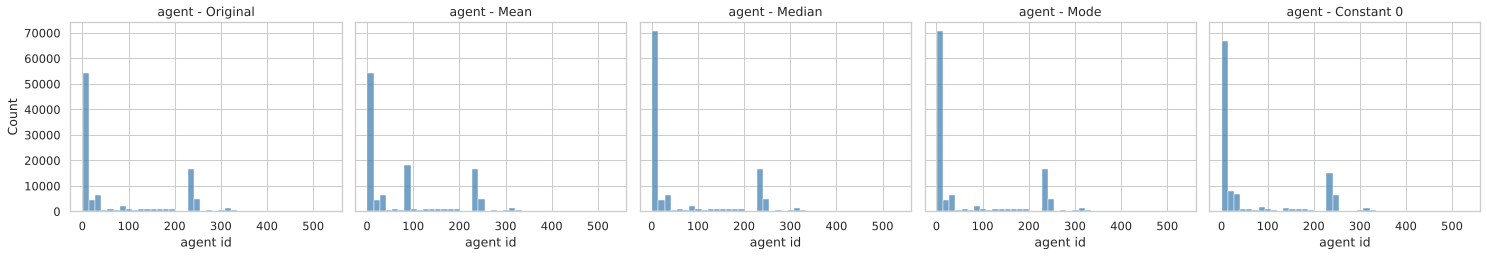

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6), sharey=True)
variants = {"Original": ag.dropna(), "Mean": ag.fillna(ag.mean()), "Median": ag.fillna(ag.median()),
            "Mode": ag.fillna(ag.mode()[0]), "Constant 0": ag.fillna(0)}
for a, (name, s) in zip(axes, variants.items()):
    sns.histplot(s, bins=40, ax=a, color="steelblue"); a.set_title(f"agent - {name}"); a.set_xlabel("agent id")
plt.tight_layout(); plt.show()

In [ ]:

df["has_agent"]   = df["agent"].notna().astype("int8")
df["has_company"] = df["company"].notna().astype("int8")
df["agent"]       = df["agent"].fillna("No_Agent")
df = df.drop(columns="company")

df_imp_demo = df.copy()
df_imp_demo["children"] = df_imp_demo["children"].fillna(df_imp_demo["children"].mode()[0]).astype(int)
df_imp_demo["country"]  = df_imp_demo["country"].fillna(df_imp_demo["country"].mode()[0])
print("Missing values left in the demo copy :", int(df_imp_demo.isna().sum().sum()))
print("Missing values still in working df   :", df.isna().sum()[lambda s: s > 0].to_dict(), "(handled in the pipeline)")

Missing values left in the demo copy : 0
Missing values still in working df   : {'children': 4, 'country': 488} (handled in the pipeline)


---
# Task 4: Duplicate Record Handling


In [ ]:
cleaning_log = [("Original dataset", len(df_raw))]

dup_mask = df.duplicated(keep="first")
print(f"Duplicate records (excluding first occurrence): {dup_mask.sum():,}  ({dup_mask.mean()*100:.2f}% of data)")
print("Cancellation split among duplicates:", dup_mask[dup_mask].index.map(df[TARGET]).value_counts().to_dict())
print("Example duplicated rows:")
display(df[df.duplicated(keep=False)].sort_values(["hotel", "lead_time", "arrival_date_day_of_month", "adr"]).head(6))

Duplicate records (excluding first occurrence): 31,998  (26.80% of data)
Cancellation split among duplicates: {1: 20199, 0: 11799}
Example duplicated rows:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_agent,has_company
84813,City Hotel,0,0,2016,March,10,2,0,2,1,0.000,0,BB,PRT,Corporate,Direct,0,0,0,A,D,0,No Deposit,No_Agent,0,Transient,55.000,1,1,Check-Out,2016-03-04,0,0
84815,City Hotel,0,0,2016,March,10,2,0,2,1,0.000,0,BB,PRT,Corporate,Direct,0,0,0,A,D,0,No Deposit,No_Agent,0,Transient,55.000,1,1,Check-Out,2016-03-04,0,0
115166,City Hotel,0,0,2017,July,27,2,1,0,2,0.000,0,SC,FRA,Direct,Direct,0,0,0,A,A,0,No Deposit,No_Agent,0,Transient,123.000,0,0,Check-Out,2017-07-03,0,0
115167,City Hotel,0,0,2017,July,27,2,1,0,2,0.000,0,SC,FRA,Direct,Direct,0,0,0,A,A,0,No Deposit,No_Agent,0,Transient,123.000,0,0,Check-Out,2017-07-03,0,0
78101,City Hotel,0,0,2015,October,40,2,0,2,1,0.000,0,BB,PRT,Direct,Direct,0,0,0,A,E,2,No Deposit,No_Agent,0,Transient-Party,145.000,0,0,Check-Out,2015-10-04,0,0
78104,City Hotel,0,0,2015,October,40,2,0,2,1,0.000,0,BB,PRT,Direct,Direct,0,0,0,A,E,2,No Deposit,No_Agent,0,Transient-Party,145.000,0,0,Check-Out,2015-10-04,0,0


In [ ]:
before = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
cleaning_log.append(("Removed exact duplicates", len(df)))
print(f"Rows before: {before:,} | rows after: {len(df):,} | removed: {before-len(df):,}")
print(f"(Exact duplicates in the untouched raw file: {df_raw.duplicated().sum():,}; the working copy finds a few more because the "
      "raw 'company' ID was replaced by the has_company flag in Task 3.)")
print("Duplicates remaining:", df.duplicated().sum())

Rows before: 119,390 | rows after: 87,392 | removed: 31,998
(Exact duplicates in the untouched raw file: 31,994; the working copy finds a few more because the raw 'company' ID was replaced by the has_company flag in Task 3.)
Duplicates remaining: 0


---
# Task 5: Outlier Detection
 We detect them with three views: boxplots (visual), the IQR rule (`Q1 − 1.5·IQR`, `Q3 + 1.5·IQR`) and the Z-score rule (`|z| > 3`).

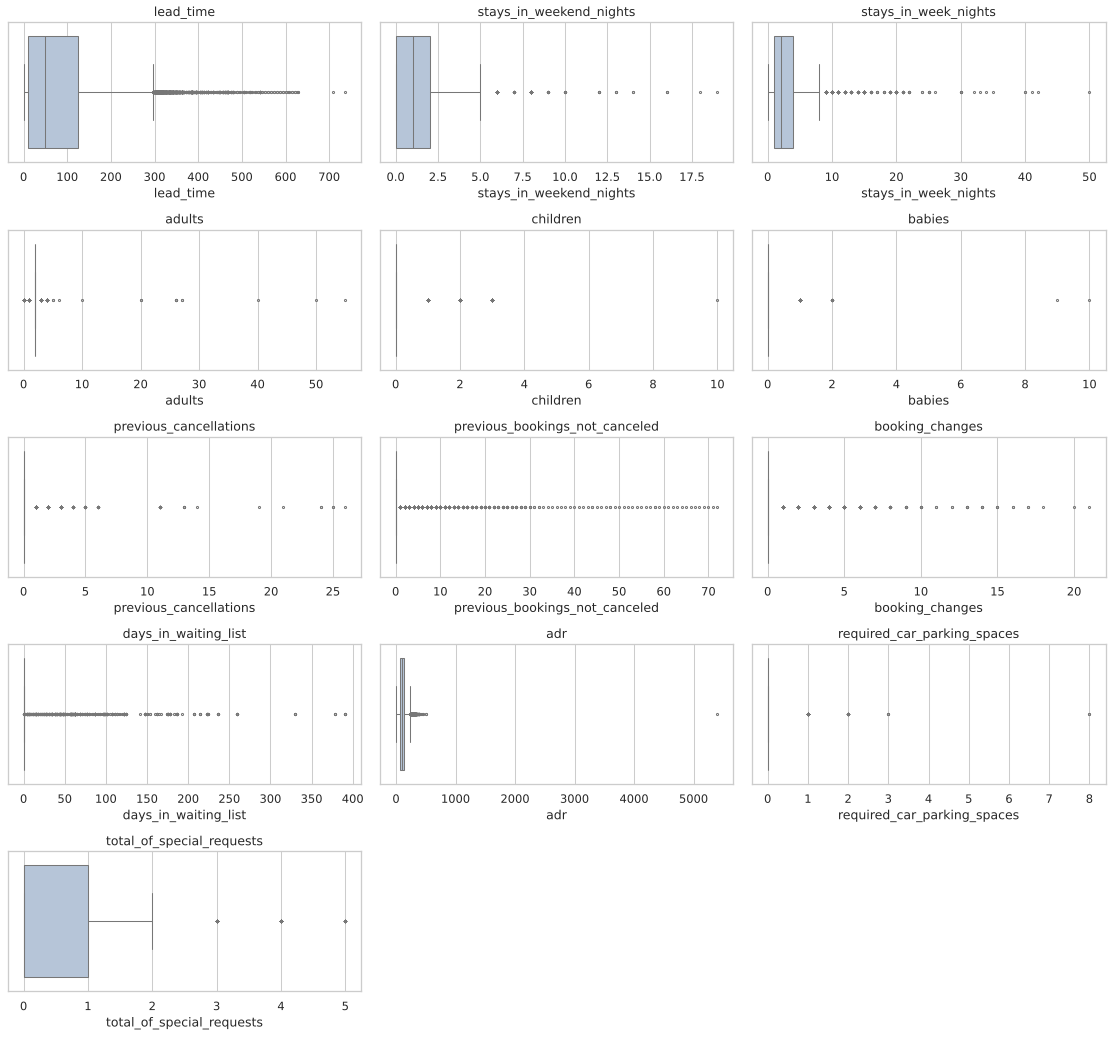

In [ ]:
OUTLIER_COLS = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
                "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
                "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"]

fig, axes = plt.subplots(5, 3, figsize=(15, 14))
for a, c in zip(axes.ravel(), OUTLIER_COLS):
    sns.boxplot(x=df[c], ax=a, color="lightsteelblue", fliersize=2); a.set_title(c)
for a in axes.ravel()[len(OUTLIER_COLS):]:
    a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return q1, q3, iqr, q1 - k * iqr, q3 + k * iqr

rows = []
for c in OUTLIER_COLS:
    s = df[c].dropna()
    q1, q3, iqr, lo, hi = iqr_bounds(s)
    n_iqr = int(((s < lo) | (s > hi)).sum())
    n_z   = int((np.abs(stats.zscore(s)) > 3).sum())
    rows.append([c, q1, q3, iqr, lo, hi, n_iqr, n_iqr / len(s) * 100, n_z, n_z / len(s) * 100, s.max()])

outlier_report = pd.DataFrame(rows, columns=["feature", "Q1", "Q3", "IQR", "lower_fence", "upper_fence",
                                             "IQR_outliers", "IQR_%", "Z>3_outliers", "Z_%", "max"]).set_index("feature")
display(outlier_report.sort_values("IQR_%", ascending=False))

,Q1,Q3,IQR,lower_fence,upper_fence,IQR_outliers,IQR_%,Z>3_outliers,Z_%,max
feature,,,,,,,,,,
adults,2.000,2.000,0.000,2.000,2.000,22895,26.198,76,0.087,55.000
booking_changes,0.000,0.000,0.000,0.000,0.000,15902,18.196,1492,1.707,21.000
children,0.000,0.000,0.000,0.000,0.000,8364,9.571,3669,4.199,10.000
required_car_parking_spaces,0.000,0.000,0.000,0.000,0.000,7313,8.368,7313,8.368,8.000
previous_bookings_not_canceled,0.000,0.000,0.000,0.000,0.000,3545,4.056,743,0.850,72.000
total_of_special_requests,0.000,1.000,1.000,-1.500,2.500,2673,3.059,356,0.407,5.000
adr,72.000,134.000,62.000,-21.000,227.000,2490,2.849,628,0.719,"5,400.000"
lead_time,11.000,125.000,114.000,-160.000,296.000,2396,2.742,1049,1.200,737.000
previous_cancellations,0.000,0.000,0.000,0.000,0.000,1685,1.928,278,0.318,26.000


Most affected attributes (>5% IQR outliers): ['adults', 'booking_changes', 'children', 'required_car_parking_spaces']


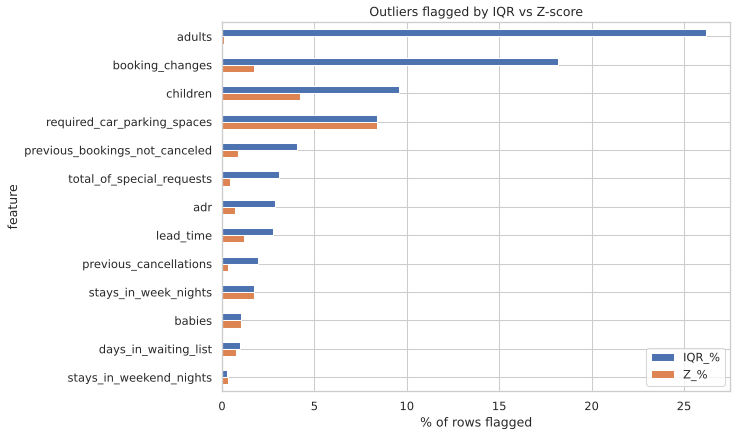

In [ ]:
rep = outlier_report.sort_values("IQR_%", ascending=False)
ax = rep[["IQR_%", "Z_%"]].plot(kind="barh", figsize=(10, 6), color=["#4c72b0", "#dd8452"])
ax.invert_yaxis(); ax.set_xlabel("% of rows flagged"); ax.set_title("Outliers flagged by IQR vs Z-score")
plt.tight_layout(); plt.show()
affected = rep.index[rep["IQR_%"] > 5].tolist()
print("Most affected attributes (>5% IQR outliers):", affected)

---
# Task 6: Outlier Treatment


In [ ]:
print("Suspicious rows - adr:")
display(df.loc[(df.adr < 0) | (df.adr >= 1000), ["hotel", "adr", "adults", "lead_time", "is_canceled"]])
print("Suspicious rows - party size:")
display(df.loc[(df.adults >= 10) | (df.children >= 10) | (df.babies >= 9), ["hotel", "adults", "children", "babies", "is_canceled"]])

Suspicious rows - adr:
Suspicious rows - party size:


,hotel,adr,adults,lead_time,is_canceled
11591,Resort Hotel,-6.380,2,195,0
38745,City Hotel,"5,400.000",2,35,1


,hotel,adults,children,babies,is_canceled
320,Resort Hotel,2,10.000,0,1
1455,Resort Hotel,40,0.000,0,1
1503,Resort Hotel,26,0.000,0,1
1558,Resort Hotel,50,0.000,0,1
1664,Resort Hotel,26,0.000,0,1
1788,Resort Hotel,26,0.000,0,1
1816,Resort Hotel,27,0.000,0,1
1859,Resort Hotel,27,0.000,0,1
1897,Resort Hotel,26,0.000,0,1
2044,Resort Hotel,26,0.000,0,1


In [ ]:
remove_mask = (df.adr < 0) | (df.adr >= 5000) | (df.adults >= 10) | (df.children >= 10) | (df.babies >= 9)
print(f"Rows removed as invalid outliers: {remove_mask.sum()}")
df = df.loc[~remove_mask].reset_index(drop=True)
cleaning_log.append(("Removed impossible adr / party-size values", len(df)))

Rows removed as invalid outliers: 18


In [ ]:
CAP_DEMO_COLS = ["lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights"]
df_cap_demo = df.copy()
fence_rows = []
for c in CAP_DEMO_COLS:
    q1, q3, iqr, lo, hi = iqr_bounds(df[c])
    df_cap_demo[c] = df[c].clip(lower=lo, upper=hi)
    fence_rows.append([c, lo, hi, int(((df[c] < lo) | (df[c] > hi)).sum())])
display(pd.DataFrame(fence_rows, columns=["feature", "lower_fence", "upper_fence", "values capped"]).set_index("feature"))

compare = pd.concat({"before": df[CAP_DEMO_COLS].describe().T[["mean", "std", "min", "max"]],
                     "after":  df_cap_demo[CAP_DEMO_COLS].describe().T[["mean", "std", "min", "max"]]}, axis=1)
compare[("before", "skew")] = df[CAP_DEMO_COLS].skew()
compare[("after", "skew")]  = df_cap_demo[CAP_DEMO_COLS].skew()
print("Before vs after capping"); display(compare)

Before vs after capping


,lower_fence,upper_fence,values capped
feature,,,
lead_time,-160.000,296.000,2383
adr,-21.000,227.000,2489
stays_in_weekend_nights,-3.000,5.000,220
stays_in_week_nights,-3.500,8.500,1530


before                        after               \
                           mean    std   min     max    mean    std   min   
lead_time                79.857 86.002 0.000 737.000  78.336 81.011 0.000   
adr                     106.297 52.005 0.000 510.000 105.363 49.174 0.000   
stays_in_weekend_nights   1.005  1.032 0.000  19.000   0.999  0.994 0.000   
stays_in_week_nights      2.625  2.053 0.000  50.000   2.577  1.807 0.000   

                                before after  
                            max   skew  skew  
lead_time               296.000  1.432 1.100  
adr                     227.000  0.864 0.505  
stays_in_weekend_nights   5.000  1.412 0.769  
stays_in_week_nights      8.500  2.692 1.007

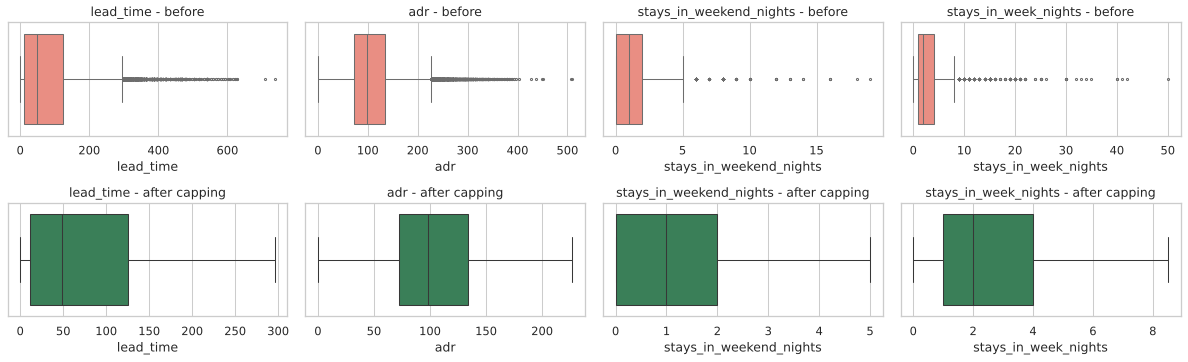

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 5))
for j, c in enumerate(CAP_DEMO_COLS):
    sns.boxplot(x=df[c], ax=axes[0, j], color="salmon", fliersize=2);          axes[0, j].set_title(f"{c} - before")
    sns.boxplot(x=df_cap_demo[c], ax=axes[1, j], color="seagreen", fliersize=2); axes[1, j].set_title(f"{c} - after capping")
plt.tight_layout(); plt.show()

In [ ]:
TRANS_COLS = ["lead_time", "adr", "days_in_waiting_list"]
trans = pd.DataFrame(index=TRANS_COLS)
trans["original skew"]   = df[TRANS_COLS].skew()
trans["IQR-capped skew"] = [df[c].clip(*iqr_bounds(df[c])[3:]).skew() for c in TRANS_COLS]
trans["log1p skew"]      = np.log1p(df[TRANS_COLS]).skew()
trans["sqrt skew"]       = np.sqrt(df[TRANS_COLS]).skew()
trans["Yeo-Johnson skew"] = pd.DataFrame(PowerTransformer("yeo-johnson").fit_transform(df[TRANS_COLS]),
                                          columns=TRANS_COLS).skew()
display(trans)

,original skew,IQR-capped skew,log1p skew,sqrt skew,Yeo-Johnson skew
lead_time,1.432,1.100,-0.716,0.350,-0.139
adr,0.864,0.505,-3.566,-0.620,0.089
days_in_waiting_list,19.394,0.000,10.683,12.551,9.930


---
# Task 7: Data Inconsistency Handling


In [ ]:
cat_check = ["hotel", "meal", "country", "market_segment", "distribution_channel", "deposit_type",
             "customer_type", "reserved_room_type", "assigned_room_type", "reservation_status"]
for c in cat_check:
    vals = df[c].dropna()
    print(f"{c:22s} unique={vals.nunique():3d} | whitespace issues={int((vals != vals.str.strip()).sum())} "
          f"| case-duplicates={vals.nunique() - vals.str.lower().nunique()}")
print()
print("meal                 :", df.meal.value_counts().to_dict())
print("distribution_channel :", df.distribution_channel.value_counts().to_dict())
print("market_segment       :", df.market_segment.value_counts().to_dict())
print("country code lengths :", df.country.dropna().str.len().value_counts().to_dict())
print("Non 3-letter country codes:", df.country[df.country.str.len() != 3].dropna().unique().tolist())

hotel                  unique=  2 | whitespace issues=0 | case-duplicates=0
meal                   unique=  5 | whitespace issues=0 | case-duplicates=0
country                unique=177 | whitespace issues=0 | case-duplicates=0
market_segment         unique=  8 | whitespace issues=0 | case-duplicates=0
distribution_channel   unique=  5 | whitespace issues=0 | case-duplicates=0
deposit_type           unique=  3 | whitespace issues=0 | case-duplicates=0
customer_type          unique=  4 | whitespace issues=0 | case-duplicates=0
reserved_room_type     unique= 10 | whitespace issues=0 | case-duplicates=0
assigned_room_type     unique= 12 | whitespace issues=0 | case-duplicates=0
reservation_status     unique=  3 | whitespace issues=0 | case-duplicates=0

meal                 : {'BB': 67959, 'SC': 9481, 'HB': 9082, 'Undefined': 492, 'FB': 360}
distribution_channel : {'TA/TO': 69133, 'Direct': 12979, 'Corporate': 5076, 'GDS': 181, 'Undefined': 5}
market_segment       : {'Online TA': 51617, '

In [ ]:
for c in cat_check:
    df[c] = df[c].str.strip()
df["country"] = df["country"].str.upper()
df["meal"] = df["meal"].replace("Undefined", "SC")
for c in ["market_segment", "distribution_channel"]:
    df[c] = df[c].replace("Undefined", np.nan)

df["country"] = df["country"].replace({"CN": "CHN", "TMP": "TLS"})

print("meal                 :", df.meal.value_counts().to_dict())
print("distribution_channel :", df.distribution_channel.value_counts(dropna=False).to_dict())
print("market_segment       :", df.market_segment.value_counts(dropna=False).to_dict())
print("Non 3-letter country codes left:", df.country[df.country.str.len() != 3].dropna().unique().tolist())

meal                 : {'BB': 67959, 'SC': 9973, 'HB': 9082, 'FB': 360}
distribution_channel : {'TA/TO': 69133, 'Direct': 12979, 'Corporate': 5076, 'GDS': 181, nan: 5}
market_segment       : {'Online TA': 51617, 'Offline TA/TO': 13882, 'Direct': 11796, 'Groups': 4941, 'Corporate': 4207, 'Complementary': 702, 'Aviation': 227, nan: 2}
Non 3-letter country codes left: []


In [ ]:

MONTH_NUM = df["arrival_date_month"].cat.codes + 1
rules = {  # column: (min allowed, max allowed)
    "lead_time": (0, 800), "arrival_date_week_number": (1, 53), "arrival_date_day_of_month": (1, 31),
    "stays_in_weekend_nights": (0, 20), "stays_in_week_nights": (0, 60), "adults": (0, 10),
    "children": (0, 10), "babies": (0, 10), "adr": (0, 5000), "required_car_parking_spaces": (0, 10),
    "total_of_special_requests": (0, 5), "days_in_waiting_list": (0, 400),
}
rng = pd.DataFrame([[c, lo, hi, int(((df[c] < lo) | (df[c] > hi)).sum())] for c, (lo, hi) in rules.items()],
                   columns=["feature", "min", "max", "violations"]).set_index("feature")
display(rng)
arrival_dt = pd.to_datetime(pd.DataFrame({"year": df.arrival_date_year, "month": MONTH_NUM, "day": df.arrival_date_day_of_month}),
                            errors="coerce")
zero_guests = (df.adults + df.children.fillna(0) + df.babies) == 0
zero_nights = (df.stays_in_weekend_nights + df.stays_in_week_nights) == 0
print("Impossible calendar dates       :", int(arrival_dt.isna().sum()))
print("Bookings with 0 guests          :", int(zero_guests.sum()))
print("Bookings with 0 nights          :", int(zero_nights.sum()))
print("Negative adr values             :", int((df.adr < 0).sum()))

Impossible calendar dates       : 0
Bookings with 0 guests          : 166
Bookings with 0 nights          : 651
Negative adr values             : 0


,min,max,violations
feature,,,
lead_time,0,800,0
arrival_date_week_number,1,53,0
arrival_date_day_of_month,1,31,0
stays_in_weekend_nights,0,20,0
stays_in_week_nights,0,60,0
adults,0,10,0
children,0,10,0
babies,0,10,0
adr,0,5000,0


In [ ]:
bad = zero_guests | zero_nights
df = df.loc[~bad].reset_index(drop=True)
cleaning_log.append(("Removed bookings with 0 guests / 0 nights", len(df)))
print(f"Removed {bad.sum()} logically invalid rows. Remaining rows: {len(df):,}")

Removed 757 logically invalid rows. Remaining rows: 86,617


---
# Task 8: Categorical Data Encoding
 ML models need numbers. The right encoder depends on the variable type:

| Type | Columns | Encoder |
|---|---|---|
| **Ordinal** (natural order) | `meal` (SC < BB < HB < FB), `arrival_date_month` | Ordinal/Label encoding with an *explicit* order |
| **Binary nominal** | `hotel` | Label encoding (0/1) |
| **Nominal** (no order) | `market_segment`, `distribution_channel`, `deposit_type`, `customer_type`, `reserved_room_type`, `assigned_room_type`, `country`, `agent` | One-Hot Encoding |

Label-encoding a nominal feature would tell the model that e.g. *Online TA* > *Direct*, which is meaningless – hence One-Hot for those.

In [ ]:
enc = df.copy()
le = LabelEncoder()
enc["hotel_label"] = le.fit_transform(enc["hotel"])
print("LabelEncoder mapping for hotel:", dict(zip(le.classes_, le.transform(le.classes_))))

meal_order = ["SC", "BB", "HB", "FB"]
enc["meal_ordinal"] = OrdinalEncoder(categories=[meal_order]).fit_transform(enc[["meal"]]).ravel()
enc["month_ordinal"] = enc["arrival_date_month"].cat.codes + 1
display(enc[["hotel", "hotel_label", "meal", "meal_ordinal", "arrival_date_month", "month_ordinal"]].drop_duplicates().head(8))

ms = LabelEncoder().fit(enc["market_segment"].dropna())
print("\nLabelEncoder on market_segment (implies a false order!):", dict(zip(ms.classes_, ms.transform(ms.classes_))))

LabelEncoder mapping for hotel: {'City Hotel': np.int64(0), 'Resort Hotel': np.int64(1)}

LabelEncoder on market_segment (implies a false order!): {'Aviation': np.int64(0), 'Complementary': np.int64(1), 'Corporate': np.int64(2), 'Direct': np.int64(3), 'Groups': np.int64(4), 'Offline TA/TO': np.int64(5), 'Online TA': np.int64(6)}


,hotel,hotel_label,meal,meal_ordinal,arrival_date_month,month_ordinal
0,Resort Hotel,1,BB,1.000,July,7
4,Resort Hotel,1,FB,3.000,July,7
6,Resort Hotel,1,HB,2.000,July,7
777,Resort Hotel,1,BB,1.000,August,8
778,Resort Hotel,1,HB,2.000,August,8
812,Resort Hotel,1,FB,3.000,August,8
1376,Resort Hotel,1,BB,1.000,September,9
1378,Resort Hotel,1,HB,2.000,September,9


In [ ]:
# --- One-Hot Encoding ---
ohe_cols = ["market_segment", "deposit_type", "customer_type"]
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
ohe_arr = ohe.fit_transform(enc[ohe_cols].fillna("Unknown"))
ohe_df = pd.DataFrame(ohe_arr, columns=ohe.get_feature_names_out(ohe_cols), index=enc.index)
print("One-Hot result shape:", ohe_df.shape)
display(pd.concat([enc[ohe_cols].head(5), ohe_df.head(5)], axis=1))

One-Hot result shape: (86617, 15)


,market_segment,deposit_type,customer_type,market_segment_Aviation,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Unknown,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,Direct,No Deposit,Transient,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000
1,Corporate,No Deposit,Transient,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000
2,Online TA,No Deposit,Transient,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000
3,Direct,No Deposit,Transient,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000
4,Direct,No Deposit,Transient,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000


In [ ]:
# --- Compare the transformed attributes ---
high_card = OneHotEncoder(sparse_output=False, min_frequency=0.01, handle_unknown="infrequent_if_exist")
rows = []
for c in ["hotel", "meal", "market_segment", "deposit_type", "customer_type", "reserved_room_type", "country", "agent"]:
    n = df[c].nunique()
    rows.append([c, n, 1, n, len(high_card.fit(df[[c]].fillna("Unknown")).get_feature_names_out())])
cmp = pd.DataFrame(rows, columns=["column", "distinct values", "columns after Label/Ordinal", "columns after full One-Hot",
                                  "columns after One-Hot (rare <1% grouped)"]).set_index("column")
display(cmp)
print("Total new columns if every nominal column is fully one-hot encoded:", int(cmp["columns after full One-Hot"].sum()))
print("Total with rare-category grouping (used in the pipeline)         :", int(cmp["columns after One-Hot (rare <1% grouped)"].sum()))

Total new columns if every nominal column is fully one-hot encoded: 539
Total with rare-category grouping (used in the pipeline)         : 55


,distinct values,columns after Label/Ordinal,columns after full One-Hot,columns after One-Hot (rare <1% grouped)
column,,,,
hotel,2,1,2,2
meal,4,1,4,4
market_segment,7,1,7,6
deposit_type,3,1,3,3
customer_type,4,1,4,4
reserved_room_type,9,1,9,8
country,176,1,176,15
agent,334,1,334,13



# Task 9: Feature Scaling
 `lead_time` ranges 0–700 while `adr` is ~100 and flags are 0/1; distance- and gradient-based models are dominated by large-scale features. We compare three scalers on columns with very different scales and outlier behaviour. (Fitted on the full data here only for comparison; the real fitting happens on training data in Task 16.)

| Scaler | Formula | Sensitive to outliers? |
|---|---|---|
| StandardScaler | (x − mean) / std | Yes |
| MinMaxScaler | (x − min) / (max − min) → [0, 1] | Very |
| RobustScaler | (x − median) / IQR | No |

In [ ]:
SCALE_COLS = ["lead_time", "adr", "stays_in_week_nights", "days_in_waiting_list"]
scalers = {"Standard": StandardScaler(), "MinMax": MinMaxScaler(), "Robust": RobustScaler()}
scaled = {n: pd.DataFrame(s.fit_transform(df[SCALE_COLS]), columns=SCALE_COLS) for n, s in scalers.items()}
scaled = {"Original": df[SCALE_COLS].reset_index(drop=True), **scaled}

summary = pd.concat({n: d.agg(["min", "max", "mean", "std", "median"]).T for n, d in scaled.items()}, axis=1)
display(summary)

Original                               Standard         \
                          min     max    mean    std median      min    max   
lead_time               0.000 709.000  80.259 86.023 50.000   -0.933  7.309   
adr                     0.000 510.000 107.204 51.292 99.000   -2.090  7.853   
stays_in_week_nights    0.000  50.000   2.642  2.035  2.000   -1.298 23.271   
days_in_waiting_list    0.000 391.000   0.750 10.031  0.000   -0.075 38.906   

                                         MinMax                           \
                       mean   std median    min   max  mean   std median   
lead_time             0.000 1.000 -0.352  0.000 1.000 0.113 0.121  0.071   
adr                  -0.000 1.000 -0.160  0.000 1.000 0.210 0.101  0.194   
stays_in_week_nights -0.000 1.000 -0.315  0.000 1.000 0.053 0.041  0.040   
days_in_waiting_list  0.000 1.000 -0.075  0.000 1.000 0.002 0.026  0.000   

                     Robust                              
                        min     max  mean    std median  
lead_time            -0.442   5.832 0.268  0.761  0.000  
adr                  -1.608   6.676 0.133  0.833  0.000  
stays_in_week_nights -0.667  16.000 0.214  0.678  0.000  
days_in_waiting_list  0.000 391.000 0.750 10.031  0.000

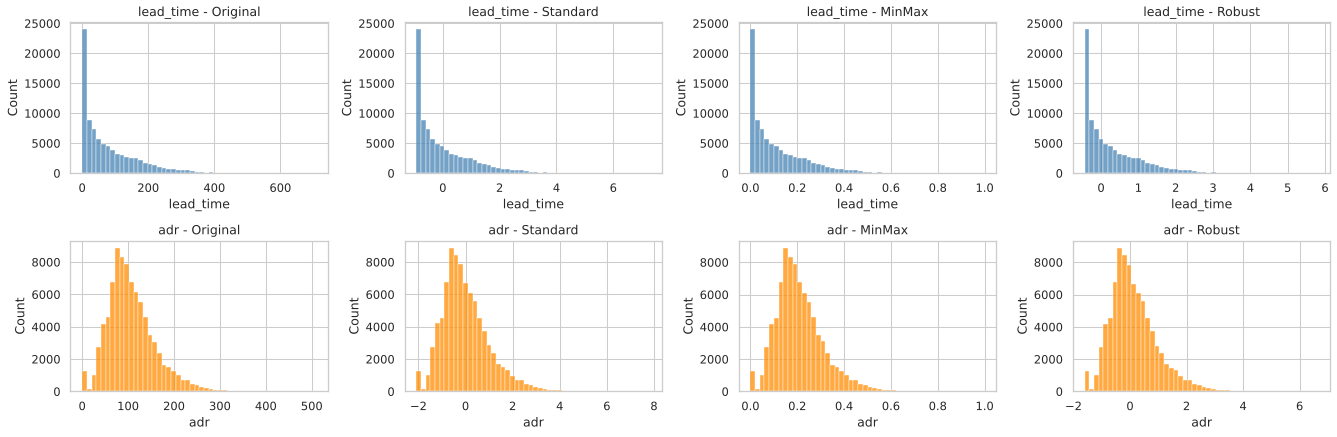

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for j, (n, d) in enumerate(scaled.items()):
    sns.histplot(d["lead_time"], bins=50, ax=axes[0, j], color="steelblue"); axes[0, j].set_title(f"lead_time - {n}")
    sns.histplot(d["adr"], bins=50, ax=axes[1, j], color="darkorange");      axes[1, j].set_title(f"adr - {n}")
plt.tight_layout(); plt.show()


# Task 10: Data Transformation


In [ ]:
num_for_skew = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
                "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
                "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"]
skew_tbl = df[num_for_skew].skew().sort_values(ascending=False).rename("skewness").to_frame()
skew_tbl["verdict"] = np.where(skew_tbl.skewness.abs() > 1, "highly skewed", "moderate / ok")
display(skew_tbl)

,skewness,verdict
previous_cancellations,34.225,highly skewed
previous_bookings_not_canceled,20.433,highly skewed
days_in_waiting_list,19.420,highly skewed
babies,9.992,highly skewed
booking_changes,5.079,highly skewed
required_car_parking_spaces,3.479,highly skewed
children,3.365,highly skewed
stays_in_week_nights,2.600,highly skewed
lead_time,1.423,highly skewed
stays_in_weekend_nights,1.336,highly skewed


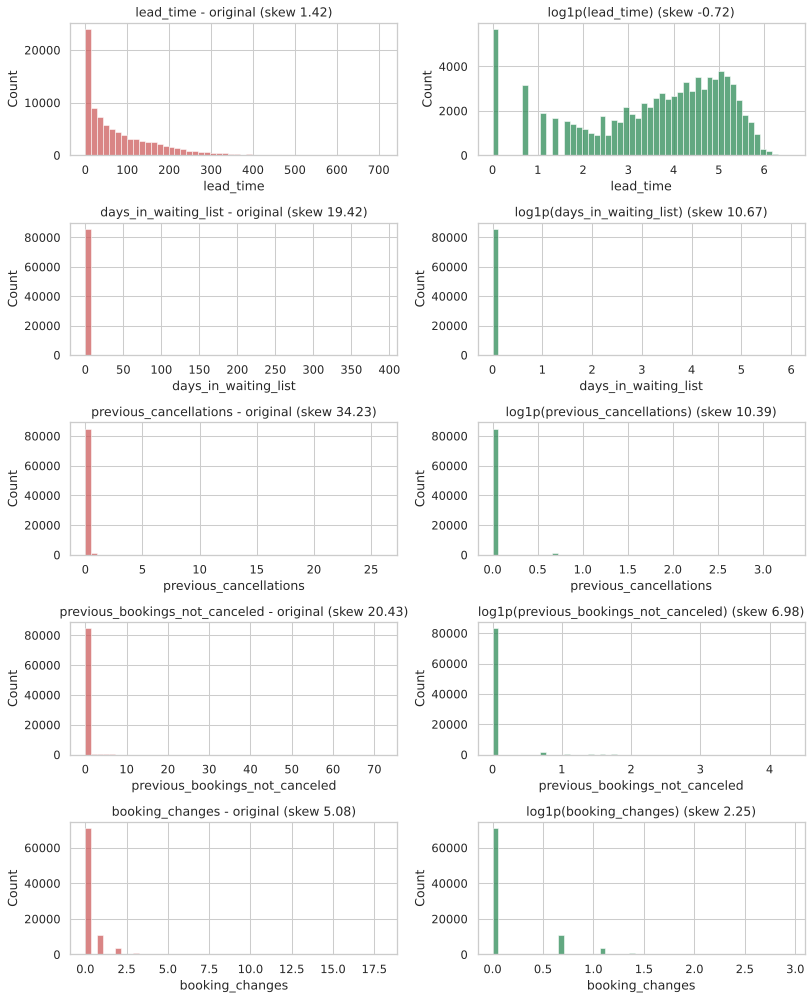

,skew before,skew after log1p
feature,,
lead_time,1.423,-0.723
days_in_waiting_list,19.420,10.674
previous_cancellations,34.225,10.388
previous_bookings_not_canceled,20.433,6.985
booking_changes,5.079,2.252


In [ ]:
LOG_COLS = ["lead_time", "days_in_waiting_list", "previous_cancellations",
            "previous_bookings_not_canceled", "booking_changes"]
fig, axes = plt.subplots(len(LOG_COLS), 2, figsize=(11, 2.7 * len(LOG_COLS)))
rows = []
for i, c in enumerate(LOG_COLS):
    sns.histplot(df[c], bins=50, ax=axes[i, 0], color="indianred");               axes[i, 0].set_title(f"{c} - original (skew {df[c].skew():.2f})")
    sns.histplot(np.log1p(df[c]), bins=50, ax=axes[i, 1], color="seagreen");      axes[i, 1].set_title(f"log1p({c}) (skew {np.log1p(df[c]).skew():.2f})")
    rows.append([c, df[c].skew(), np.log1p(df[c]).skew()])
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows, columns=["feature", "skew before", "skew after log1p"]).set_index("feature"))


# Task 11: Date and Time Preprocessing


In [ ]:
month_num = df["arrival_date_month"].cat.codes + 1
df["arrival_month_num"] = month_num.astype(int)
df["arrival_date"] = pd.to_datetime(pd.DataFrame({"year": df.arrival_date_year,
                                                  "month": df.arrival_month_num,
                                                  "day": df.arrival_date_day_of_month}))

# Extract year / month / day and further date features
df["arrival_weekday"]    = df["arrival_date"].dt.dayofweek               # 0 = Monday
df["arrival_is_weekend"] = (df["arrival_weekday"] >= 5).astype(int)
df["arrival_quarter"]    = df["arrival_date"].dt.quarter
season_map = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
df["arrival_season"]     = df["arrival_month_num"].map(season_map)
# Booking date = arrival date minus lead time
df["booking_date"]    = df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")
df["booking_year"]    = df["booking_date"].dt.year
df["booking_month"]   = df["booking_date"].dt.month
df["booking_weekday"] = df["booking_date"].dt.dayofweek

display(df[["arrival_date", "arrival_date_year", "arrival_month_num", "arrival_date_day_of_month", "arrival_weekday",
            "arrival_is_weekend", "arrival_quarter", "arrival_season", "booking_date", "lead_time"]].head())
print("Arrival range:", df.arrival_date.min().date(), "->", df.arrival_date.max().date())

Arrival range: 2015-07-01 -> 2017-08-31


,arrival_date,arrival_date_year,arrival_month_num,arrival_date_day_of_month,arrival_weekday,arrival_is_weekend,arrival_quarter,arrival_season,booking_date,lead_time
0,2015-07-01,2015,7,1,2,0,3,Summer,2015-06-24,7
1,2015-07-01,2015,7,1,2,0,3,Summer,2015-06-18,13
2,2015-07-01,2015,7,1,2,0,3,Summer,2015-06-17,14
3,2015-07-01,2015,7,1,2,0,3,Summer,2015-07-01,0
4,2015-07-01,2015,7,1,2,0,3,Summer,2015-06-22,9


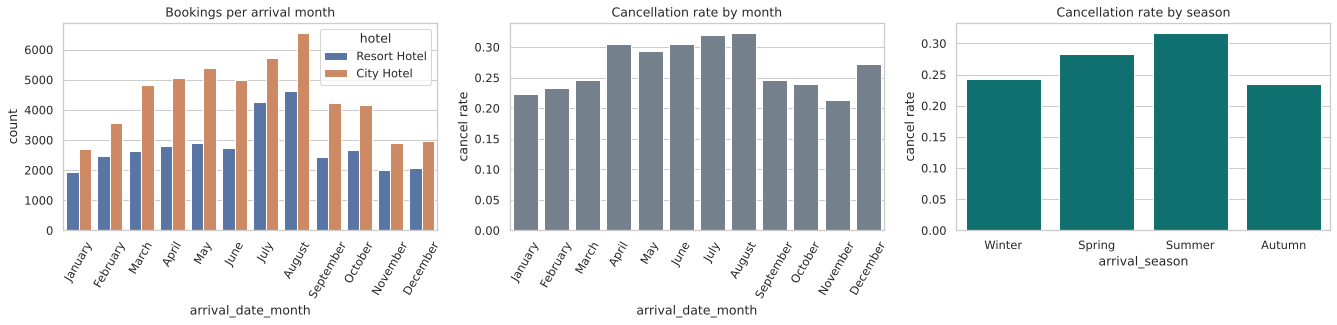

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
order = MONTHS
sns.countplot(data=df, x="arrival_date_month", hue="hotel", order=order, ax=axes[0])
axes[0].set_title("Bookings per arrival month"); axes[0].tick_params(axis="x", rotation=60)
rate_m = df.groupby("arrival_date_month", observed=True)[TARGET].mean().reindex(order)
sns.barplot(x=rate_m.index, y=rate_m.values, ax=axes[1], color="slategray")
axes[1].set_title("Cancellation rate by month"); axes[1].tick_params(axis="x", rotation=60); axes[1].set_ylabel("cancel rate")
rate_s = df.groupby("arrival_season")[TARGET].mean().reindex(["Winter", "Spring", "Summer", "Autumn"])
sns.barplot(x=rate_s.index, y=rate_s.values, ax=axes[2], color="teal")
axes[2].set_title("Cancellation rate by season"); axes[2].set_ylabel("cancel rate")
plt.tight_layout(); plt.show()

---
# Task 12: Feature Engineering
New attributes that summarise or re-express existing ones so the model can learn patterns more easily:

| New feature | Definition | Why it is useful |
|---|---|---|
| `total_nights` | weekend + week nights | overall length of stay |
| `total_guests` | adults + children + babies | party size |
| `lead_time_category` | Last-minute / Short / Medium / Long / Very long | non-linear effect of booking lead time, ordinal |
| `is_family` | children or babies present | families behave differently |
| `weekend_night_ratio` | weekend nights / total nights | leisure vs business style stay |
| `has_previous_cancellations` | any earlier cancellation | strong behavioural signal |
| `has_special_requests`, `has_parking` | flags | engaged guests rarely cancel |
| `adr_per_person` | adr / total_guests | price level per guest |
| `is_domestic` | country = PRT (hotels are in Portugal) | domestic guests cancel differently |
| `room_type_changed` | reserved ≠ assigned room | *created for analysis only* – assigned room is known only at/after check-in, so it is excluded later (Task 13) |

In [ ]:
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]      # NaN if children is missing -> imputed in pipeline

bins   = [-1, 7, 30, 90, 180, np.inf]
labels = ["Last-minute", "Short", "Medium", "Long", "Very long"]
df["lead_time_category"] = pd.cut(df["lead_time"], bins=bins, labels=labels).astype(str)

df["is_family"]                 = ((df["children"] > 0) | (df["babies"] > 0)).astype(int)
df["weekend_night_ratio"]       = df["stays_in_weekend_nights"] / df["total_nights"]
df["has_previous_cancellations"] = (df["previous_cancellations"] > 0).astype(int)
df["has_special_requests"]      = (df["total_of_special_requests"] > 0).astype(int)
df["has_parking"]               = (df["required_car_parking_spaces"] > 0).astype(int)
df["adr_per_person"]            = df["adr"] / df["total_guests"]
df["is_domestic"]               = (df["country"] == "PRT").astype(int)
df["room_type_changed"]         = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)

new_feats = ["total_nights", "total_guests", "lead_time_category", "is_family", "weekend_night_ratio",
             "has_previous_cancellations", "has_special_requests", "has_parking", "adr_per_person",
             "is_domestic", "room_type_changed"]
display(df[new_feats].head())
print("Shape now:", df.shape)

Shape now: (86617, 54)


,total_nights,total_guests,lead_time_category,is_family,weekend_night_ratio,has_previous_cancellations,has_special_requests,has_parking,adr_per_person,is_domestic,room_type_changed
0,1,1.000,Last-minute,0,0.000,0,0,0,75.000,0,1
1,1,1.000,Short,0,0.000,0,0,0,75.000,0,0
2,2,2.000,Short,0,0.000,0,1,0,49.000,0,0
3,2,2.000,Last-minute,0,0.000,0,0,0,53.500,1,0
4,2,2.000,Short,0,0.000,0,1,0,51.500,1,0


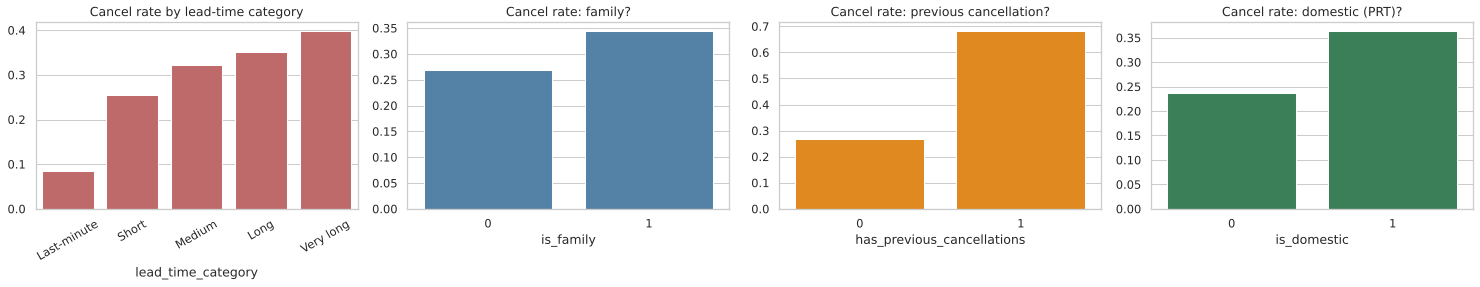

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
r = df.groupby("lead_time_category")[TARGET].mean().reindex(labels)
sns.barplot(x=r.index, y=r.values, ax=axes[0], color="indianred"); axes[0].set_title("Cancel rate by lead-time category"); axes[0].tick_params(axis="x", rotation=30)
r = df.groupby("is_family")[TARGET].mean(); sns.barplot(x=r.index, y=r.values, ax=axes[1], color="steelblue"); axes[1].set_title("Cancel rate: family?")
r = df.groupby("has_previous_cancellations")[TARGET].mean(); sns.barplot(x=r.index, y=r.values, ax=axes[2], color="darkorange"); axes[2].set_title("Cancel rate: previous cancellation?")
r = df.groupby("is_domestic")[TARGET].mean(); sns.barplot(x=r.index, y=r.values, ax=axes[3], color="seagreen"); axes[3].set_title("Cancel rate: domestic (PRT)?")
plt.tight_layout(); plt.show()

---
# Task 13: Feature Selection
Steps: (1) remove leakage / not-available-at-booking features, (2) correlation analysis + heatmap, (3) drop one feature from each highly-correlated pair, (4) Variance Threshold, (5) final list.

In [ ]:
# Step 1 - features that must NOT be used as inputs
exclude_leak = {
    "reservation_status": "reveals the final outcome (Canceled / Check-Out / No-Show)",
    "reservation_status_date": "date of the final outcome",
    "assigned_room_type": "assigned at/after check-in, not known when the booking is made",
    "room_type_changed": "derived from assigned_room_type",
    "company": "dropped in Task 3 (94% missing)",
}
display(pd.Series(exclude_leak, name="reason").to_frame())

,reason
reservation_status,reveals the final outcome (Canceled / Check-Ou...
reservation_status_date,date of the final outcome
assigned_room_type,"assigned at/after check-in, not known when the..."
room_type_changed,derived from assigned_room_type
company,dropped in Task 3 (94% missing)


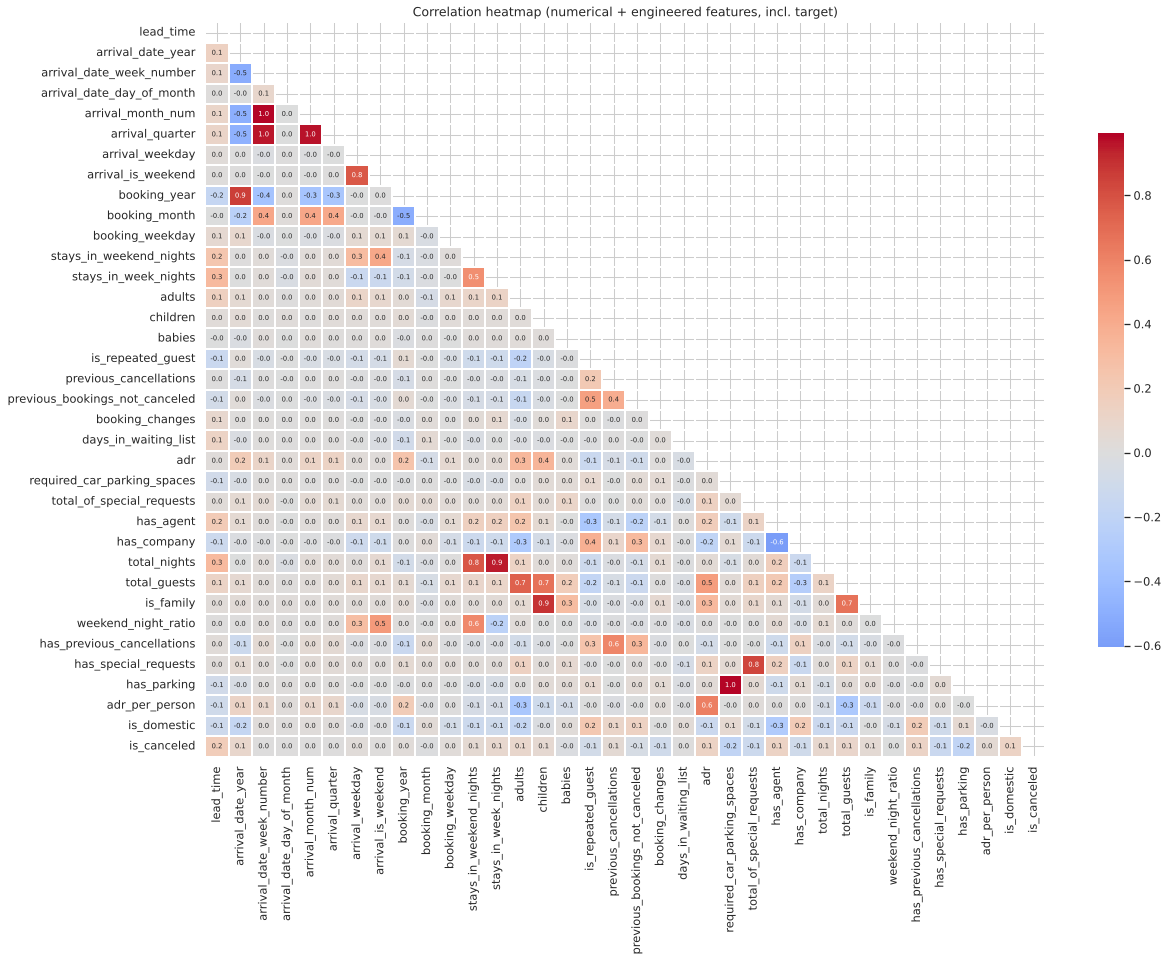

In [ ]:
num_candidates = ["lead_time", "arrival_date_year", "arrival_date_week_number", "arrival_date_day_of_month",
                  "arrival_month_num", "arrival_quarter", "arrival_weekday", "arrival_is_weekend", "booking_year",
                  "booking_month", "booking_weekday", "stays_in_weekend_nights", "stays_in_week_nights", "adults",
                  "children", "babies", "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
                  "booking_changes", "days_in_waiting_list", "adr", "required_car_parking_spaces",
                  "total_of_special_requests", "has_agent", "has_company", "total_nights", "total_guests", "is_family",
                  "weekend_night_ratio", "has_previous_cancellations", "has_special_requests", "has_parking",
                  "adr_per_person", "is_domestic"]
corr = df[num_candidates + [TARGET]].corr()

plt.figure(figsize=(17, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 6.5},
            linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Correlation heatmap (numerical + engineered features, incl. target)"); plt.tight_layout(); plt.show()

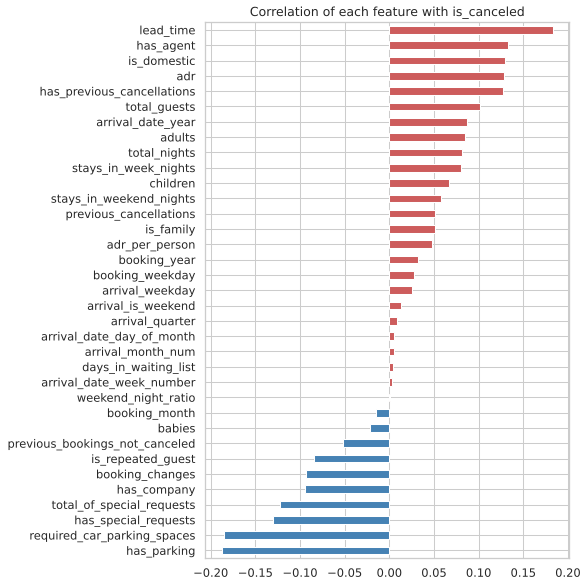

,feature_1,feature_2,correlation
0,arrival_date_week_number,arrival_month_num,0.995
1,required_car_parking_spaces,has_parking,0.990
2,arrival_month_num,arrival_quarter,0.966
3,arrival_date_week_number,arrival_quarter,0.961
4,stays_in_week_nights,total_nights,0.949
5,children,is_family,0.894
6,arrival_date_year,booking_year,0.859
7,total_of_special_requests,has_special_requests,0.843


In [ ]:
corr_target = corr[TARGET].drop(TARGET)
plt.figure(figsize=(8, 8))
corr_target.sort_values().plot(kind="barh", color=np.where(corr_target.sort_values() > 0, "indianred", "steelblue"))
plt.title("Correlation of each feature with is_canceled"); plt.tight_layout(); plt.show()

# Highly correlated pairs |r| > 0.8
cf = corr.drop(index=TARGET, columns=TARGET)
pairs = [(a, b, cf.loc[a, b]) for i, a in enumerate(cf.columns) for b in cf.columns[i + 1:] if abs(cf.loc[a, b]) > 0.8]
pairs = sorted(pairs, key=lambda t: -abs(t[2]))
pairs_df = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "correlation"])
display(pairs_df)

In [ ]:
# For every correlated pair keep the feature that is more correlated with the target, drop the other (greedy)
drop_corr = []
for a, b, r in pairs:
    if a in drop_corr or b in drop_corr:
        continue
    drop_corr.append(a if abs(corr_target[a]) < abs(corr_target[b]) else b)
print("Dropped because of high correlation:", drop_corr)

Dropped because of high correlation: ['arrival_date_week_number', 'required_car_parking_spaces', 'arrival_month_num', 'stays_in_week_nights', 'is_family', 'booking_year', 'total_of_special_requests']


In [ ]:
# Variance Threshold (on MinMax-scaled data, otherwise variance just reflects the unit of measurement)
remaining_num = [c for c in num_candidates if c not in drop_corr]
X_mm = MinMaxScaler().fit_transform(df[remaining_num].fillna(0))
vt = VarianceThreshold(threshold=0.01).fit(X_mm)
var_tbl = pd.DataFrame({"scaled_variance": vt.variances_, "|corr with target|": corr_target[remaining_num].abs().values,
                        "kept_by_VT": vt.get_support()}, index=remaining_num).sort_values("scaled_variance")
display(var_tbl.head(12))

# Low variance alone is not a reason to drop a feature that is clearly related to the target
drop_lowvar = var_tbl[(~var_tbl.kept_by_VT) & (var_tbl["|corr with target|"] < 0.02)].index.tolist()
print("Low variance AND almost no relation to target -> dropped:", drop_lowvar)
print("Low variance but informative -> kept          :", var_tbl[(~var_tbl.kept_by_VT) & (var_tbl["|corr with target|"] >= 0.02)].index.tolist())

Low variance AND almost no relation to target -> dropped: ['days_in_waiting_list']
Low variance but informative -> kept          : ['previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'total_nights', 'babies', 'stays_in_weekend_nights', 'adr_per_person', 'adults']


,scaled_variance,|corr with target|,kept_by_VT
previous_cancellations,0.000,0.051,False
previous_bookings_not_canceled,0.001,0.052,False
days_in_waiting_list,0.001,0.005,False
booking_changes,0.002,0.094,False
total_nights,0.002,0.081,False
babies,0.003,0.021,False
stays_in_weekend_nights,0.003,0.058,False
adr_per_person,0.003,0.048,False
adults,0.007,0.085,False
adr,0.010,0.128,True


In [ ]:
numeric_selected = [c for c in remaining_num if c not in drop_lowvar]
ordinal_selected = ["hotel", "meal", "lead_time_category"]                       # binary / ordinal categoricals
nominal_selected = ["market_segment", "distribution_channel", "deposit_type", "customer_type",
                    "reserved_room_type", "country", "agent", "arrival_season"]
selected_features = numeric_selected + ordinal_selected + nominal_selected

print(f"{len(selected_features)} features selected "
      f"({len(numeric_selected)} numerical/binary, {len(ordinal_selected)} ordinal, {len(nominal_selected)} nominal)\n")
print("Numerical/binary:", numeric_selected)
print("Ordinal         :", ordinal_selected)
print("Nominal         :", nominal_selected)
assert not set(selected_features) & set(exclude_leak), "leakage column slipped in!"

38 features selected (27 numerical/binary, 3 ordinal, 8 nominal)

Numerical/binary: ['lead_time', 'arrival_date_year', 'arrival_date_day_of_month', 'arrival_quarter', 'arrival_weekday', 'arrival_is_weekend', 'booking_month', 'booking_weekday', 'stays_in_weekend_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'adr', 'has_agent', 'has_company', 'total_nights', 'total_guests', 'weekend_night_ratio', 'has_previous_cancellations', 'has_special_requests', 'has_parking', 'adr_per_person', 'is_domestic']
Ordinal         : ['hotel', 'meal', 'lead_time_category']
Nominal         : ['market_segment', 'distribution_channel', 'deposit_type', 'customer_type', 'reserved_room_type', 'country', 'agent', 'arrival_season']


**Result:** Redundant features (e.g. week number vs. month, component nights vs. totals, binary flags vs. their counts) were removed using correlation, near-constant uninformative features were removed with the Variance Threshold, and outcome-revealing columns were excluded outright.

---
# Task 14: Imbalanced Dataset Handling – Class Distribution Analysis


            class  count  percent
Not cancelled (0)  62646   72.330
    Cancelled (1)  23971   27.670
Imbalance ratio (majority : minority) = 2.61 : 1


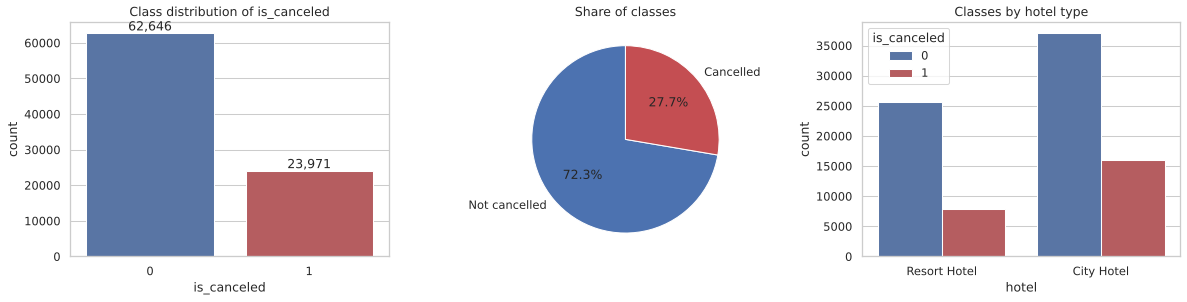

In [ ]:
counts = df[TARGET].value_counts().sort_index()
pct = df[TARGET].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"class": ["Not cancelled (0)", "Cancelled (1)"], "count": counts.values, "percent": pct.round(2).values}).to_string(index=False))
print(f"Imbalance ratio (majority : minority) = {counts.max() / counts.min():.2f} : 1")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.countplot(x=df[TARGET], ax=axes[0], palette=["#4c72b0", "#c44e52"]); axes[0].set_title("Class distribution of is_canceled")
for p in axes[0].patches: axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
axes[1].pie(counts, labels=["Not cancelled", "Cancelled"], autopct="%1.1f%%", colors=["#4c72b0", "#c44e52"], startangle=90); axes[1].set_title("Share of classes")
sns.countplot(data=df, x="hotel", hue=TARGET, ax=axes[2], palette=["#4c72b0", "#c44e52"]); axes[2].set_title("Classes by hotel type")
plt.tight_layout(); plt.show()

---
# Task 15: Train-Test Splitting
* Independent variables **X** = the selected features (no `reservation_status`, no `reservation_status_date`).
* Dependent variable **y** = `is_canceled`.
* **80 / 20** split, **stratified** so both parts keep the same cancellation ratio.
* The split happens **before** any statistic is learned, so imputers, cappers, scalers and encoders will see only `X_train`.

In [ ]:
df_model = df.copy()
X = df_model[selected_features]
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(pd.DataFrame({"full data": y.value_counts(normalize=True), "train": y_train.value_counts(normalize=True),
                    "test": y_test.value_counts(normalize=True)}).round(4))
print("Row overlap between train and test indices:", len(set(X_train.index) & set(X_test.index)))
print("Missing values in X_train (to be imputed in pipeline):", X_train.isna().sum()[lambda s: s > 0].to_dict())

X_train: (69293, 38) | X_test: (17324, 38)
             full data  train  test
is_canceled                        
0                0.723  0.723 0.723
1                0.277  0.277 0.277
Row overlap between train and test indices: 0
Missing values in X_train (to be imputed in pipeline): {'children': 4, 'total_guests': 4, 'adr_per_person': 4, 'market_segment': 2, 'distribution_channel': 4, 'country': 356}


---
# Task 16: Development of the Preprocessing Pipeline
A `ColumnTransformer` applies a dedicated `Pipeline` to each group of columns. **Every statistic is learned on `X_train` only** (`fit`), then applied to train and test (`transform`).

| Group | Steps | Reason |
|---|---|---|
| Skewed counts (`lead_time`, `days_in_waiting_list`, `previous_*`, `booking_changes`) | median impute → `log1p` → StandardScaler | Task 10 |
| Capped continuous (`adr`, `total_nights`, `adr_per_person`, stay nights) | median impute → **IQR capping** (fences learned on train) → RobustScaler | Tasks 5, 6, 9 |
| Bounded calendar numerics | median impute → MinMaxScaler | bounded ranges |
| Small counts | median impute → StandardScaler | |
| Binary flags | mode impute → passthrough | already 0/1 |
| Ordinal (`hotel`, `meal`, `lead_time_category`) | mode impute → OrdinalEncoder (explicit order) → MinMaxScaler | Task 8 |
| Nominal | mode impute → One-Hot (`min_frequency=0.01`, unseen-safe) | Task 8 |

In [ ]:
class IQRCapper(BaseEstimator, TransformerMixin):
    """Caps each column at [Q1 - k*IQR, Q3 + k*IQR]. Fences are learned in fit() -> no leakage."""
    def __init__(self, factor=1.5):
        self.factor = factor
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        iqr = q3 - q1
        self.lower_ = (q1 - self.factor * iqr).values
        self.upper_ = (q3 + self.factor * iqr).values
        self.n_features_in_ = X.shape[1]
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

# ---- feature groups (only those that survived feature selection) ----
pick = lambda cols: [c for c in cols if c in numeric_selected]
log_cols    = pick(["lead_time", "days_in_waiting_list", "previous_cancellations", "previous_bookings_not_canceled", "booking_changes"])
cap_cols    = pick(["adr", "total_nights", "adr_per_person", "stays_in_weekend_nights", "stays_in_week_nights"])
minmax_cols = pick(["arrival_date_year", "arrival_date_week_number", "arrival_date_day_of_month", "arrival_month_num",
                    "arrival_quarter", "arrival_weekday", "booking_year", "booking_month", "booking_weekday"])
std_cols    = pick(["adults", "children", "babies", "total_guests", "required_car_parking_spaces",
                    "total_of_special_requests", "weekend_night_ratio"])
binary_flag_cols = pick(["is_repeated_guest", "has_agent", "has_company", "is_family", "has_previous_cancellations",
                         "has_special_requests", "has_parking", "is_domestic", "arrival_is_weekend"])
covered = log_cols + cap_cols + minmax_cols + std_cols + binary_flag_cols
assert set(covered) == set(numeric_selected), set(numeric_selected) ^ set(covered)

ordinal_categories = [["City Hotel", "Resort Hotel"], ["SC", "BB", "HB", "FB"], ["Last-minute", "Short", "Medium", "Long", "Very long"]]

num_median = lambda: SimpleImputer(strategy="median")
log1p = lambda: FunctionTransformer(np.log1p, feature_names_out="one-to-one")

transformers = [
    ("log_counts", Pipeline([("impute", num_median()), ("log1p", log1p()), ("scale", StandardScaler())]), log_cols),
    ("capped_cont", Pipeline([("impute", num_median()), ("cap", IQRCapper()), ("scale", RobustScaler())]), cap_cols),
    ("calendar", Pipeline([("impute", num_median()), ("scale", MinMaxScaler())]), minmax_cols),
    ("small_counts", Pipeline([("impute", num_median()), ("scale", StandardScaler())]), std_cols),
    ("binary_flags", Pipeline([("impute", SimpleImputer(strategy="most_frequent"))]), binary_flag_cols),
    ("ordinal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OrdinalEncoder(categories=ordinal_categories, handle_unknown="use_encoded_value", unknown_value=-1)),
                          ("scale", MinMaxScaler())]), ordinal_selected),
    ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False))]),
     nominal_selected),
]
preprocessor = ColumnTransformer([t for t in transformers if len(t[2]) > 0], verbose_feature_names_out=False)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_counts', ...), ('capped_cont', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features 

In [ ]:

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_train_proc = pd.DataFrame(X_train_proc, columns=feature_names, index=X_train.index)
X_test_proc  = pd.DataFrame(X_test_proc,  columns=feature_names, index=X_test.index)

print("Processed train:", X_train_proc.shape, "| processed test:", X_test_proc.shape)
print("Missing values  - train:", int(X_train_proc.isna().sum().sum()), "| test:", int(X_test_proc.isna().sum().sum()))
print("Non-numeric columns:", int((X_train_proc.dtypes == object).sum()))
display(X_train_proc.head())

Processed train: (69293, 87) | processed test: (17324, 87)
Missing values  - train: 0 | test: 0
Non-numeric columns: 0


,lead_time,previous_cancellations,previous_bookings_not_canceled,booking_changes,adr,total_nights,adr_per_person,stays_in_weekend_nights,arrival_date_year,arrival_date_day_of_month,arrival_quarter,arrival_weekday,booking_month,booking_weekday,adults,children,babies,total_guests,weekend_night_ratio,is_repeated_guest,has_agent,has_company,has_previous_cancellations,has_special_requests,has_parking,is_domestic,arrival_is_weekend,hotel,meal,lead_time_category,...,country_BRA,country_CHE,country_CHN,country_DEU,country_ESP,country_FRA,country_GBR,country_IRL,country_ITA,country_NLD,country_PRT,country_USA,country_infrequent_sklearn,agent_1,agent_14,agent_240,agent_241,agent_250,agent_28,agent_40,agent_6,agent_7,agent_8,agent_9,agent_No_Agent,agent_infrequent_sklearn,arrival_season_Autumn,arrival_season_Spring,arrival_season_Summer,arrival_season_Winter
5735,0.297,-0.127,-0.178,-0.440,2.080,0.333,0.629,0.500,0.500,0.667,0.667,1.000,0.455,0.000,2.221,1.885,-0.103,2.809,0.841,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.333,0.500,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000
14822,-0.604,-0.127,-0.178,-0.440,-0.721,0.000,-0.783,0.500,0.000,0.133,1.000,0.833,0.909,0.000,0.243,-0.306,-0.103,-0.039,1.436,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,1.000,0.333,0.250,...,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
17308,-1.759,-0.127,-0.178,-0.440,-0.242,-0.667,-0.277,-0.500,0.500,0.367,0.000,0.833,0.182,0.667,0.243,-0.306,-0.103,-0.039,-0.946,0.000,1.000,0.000,0.000,0.000,1.000,1.000,1.000,1.000,0.333,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
85785,0.897,-0.127,-0.178,1.533,0.073,-0.333,0.056,-0.500,1.000,0.533,0.667,0.500,0.182,0.500,-1.734,1.885,-0.103,-0.039,-0.946,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.750,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000
73434,0.525,-0.127,-0.178,-0.440,0.045,1.333,-0.553,0.500,0.500,0.633,1.000,0.167,0.818,0.833,-1.734,4.076,-0.103,1.385,0.075,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.667,0.500,...,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000


In [ ]:
cap = preprocessor.named_transformers_["capped_cont"].named_steps["cap"]
print("IQR cap fences learned on the training set")
display(pd.DataFrame({"lower": cap.lower_, "upper": cap.upper_}, index=cap_cols))
print("Medians used for imputation (skewed counts):",
      dict(zip(log_cols, preprocessor.named_transformers_["log_counts"].named_steps["impute"].statistics_.round(2))))
print("Mode used for country:", preprocessor.named_transformers_["nominal"].named_steps["impute"].statistics_[nominal_selected.index("country")])

chk = pd.DataFrame({"train mean": X_train_proc[log_cols + std_cols].mean(), "train std": X_train_proc[log_cols + std_cols].std(),
                    "test mean": X_test_proc[log_cols + std_cols].mean(), "test std": X_test_proc[log_cols + std_cols].std()})
print("\nStandardScaler columns: train ~ (0, 1) by construction; test is close but NOT exactly (proof it was not refitted on test)")
display(chk)

IQR cap fences learned on the training set
Medians used for imputation (skewed counts): {'lead_time': np.float64(50.0), 'previous_cancellations': np.float64(0.0), 'previous_bookings_not_canceled': np.float64(0.0), 'booking_changes': np.float64(0.0)}
Mode used for country: PRT

StandardScaler columns: train ~ (0, 1) by construction; test is close but NOT exactly (proof it was not refitted on test)


,lower,upper
adr,-19.790,227.650
total_nights,-2.500,9.500
adr_per_person,-5.625,111.375
stays_in_weekend_nights,-3.000,5.000


,train mean,train std,test mean,test std
lead_time,0.000,1.000,-0.001,0.995
previous_cancellations,-0.000,1.000,0.006,1.017
previous_bookings_not_canceled,-0.000,1.000,-0.001,1.000
booking_changes,0.000,1.000,0.015,1.015
adults,-0.000,1.000,-0.006,0.990
children,-0.000,1.000,-0.004,0.992
babies,0.000,1.000,-0.004,0.986
total_guests,-0.000,1.000,-0.008,0.989
weekend_night_ratio,0.000,1.000,0.005,1.006


In [ ]:
# Save the final preprocessed training / testing datasets
train_out = X_train_proc.assign(is_canceled=y_train.values)
test_out  = X_test_proc.assign(is_canceled=y_test.values)
train_out.to_csv("hotel_train_preprocessed.csv", index=False)
test_out.to_csv("hotel_test_preprocessed.csv", index=False)
print("Saved hotel_train_preprocessed.csv", train_out.shape, "and hotel_test_preprocessed.csv", test_out.shape)

Saved hotel_train_preprocessed.csv (69293, 88) and hotel_test_preprocessed.csv (17324, 88)


---
# Task 14 (continued): Random Oversampling and SMOTE on the Training Data
* **Random Oversampling** duplicates minority-class rows until classes are equal.
* **SMOTE** creates *new synthetic* minority rows by interpolating between a minority sample and one of its nearest minority neighbours.
* Resampling is applied **only to `X_train_proc`/`y_train`**; the test set stays untouched so evaluation reflects real-world class proportions.

Test set (unchanged): {0: 12530, 1: 4794}


,Original train,Random Oversampling,SMOTE
Not cancelled (0),50116,50116,50116
Cancelled (1),19177,50116,50116


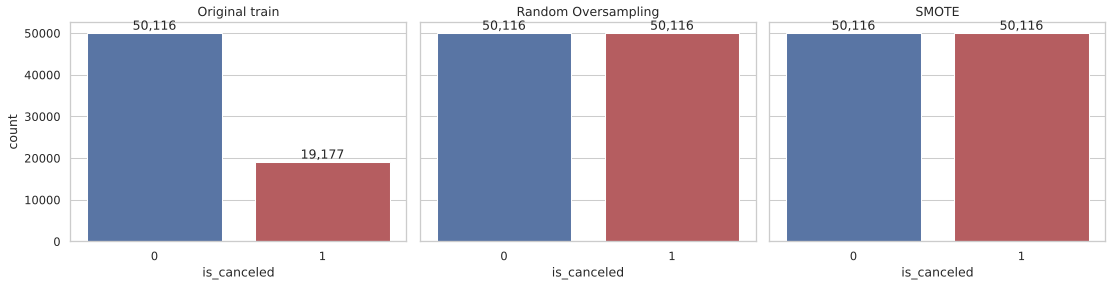

In [ ]:
ros = RandomOverSampler(random_state=RANDOM_STATE)
X_ros, y_ros = ros.fit_resample(X_train_proc, y_train)

smote = SMOTE(random_state=RANDOM_STATE)
X_smote, y_smote = smote.fit_resample(X_train_proc, y_train)

dist = pd.DataFrame({"Original train": y_train.value_counts(), "Random Oversampling": pd.Series(y_ros).value_counts(),
                     "SMOTE": pd.Series(y_smote).value_counts()}).sort_index()
dist.index = ["Not cancelled (0)", "Cancelled (1)"]
display(dist)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (n, s) in zip(axes, {"Original train": y_train, "Random Oversampling": y_ros, "SMOTE": y_smote}.items()):
    sns.countplot(x=pd.Series(s), ax=a, palette=["#4c72b0", "#c44e52"]); a.set_title(n); a.set_xlabel("is_canceled")
    for p in a.patches: a.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()
print("Test set (unchanged):", y_test.value_counts().to_dict())

In [ ]:
# Does balancing help? Quick check with one model, evaluated on the untouched test set
def evaluate(name, Xt, yt):
    m = HistGradientBoostingClassifier(max_iter=150, random_state=RANDOM_STATE).fit(Xt, yt)
    p, proba = m.predict(X_test_proc), m.predict_proba(X_test_proc)[:, 1]
    return [name, accuracy_score(y_test, p), precision_score(y_test, p), recall_score(y_test, p),
            f1_score(y_test, p), roc_auc_score(y_test, proba)]

res = pd.DataFrame([evaluate("Original (imbalanced)", X_train_proc, y_train),
                    evaluate("Random Oversampling", X_ros, y_ros),
                    evaluate("SMOTE", X_smote, y_smote)],
                   columns=["training data", "accuracy", "precision", "recall", "F1", "ROC-AUC"]).set_index("training data")
display(res)

,accuracy,precision,recall,F1,ROC-AUC
training data,,,,,
Original (imbalanced),0.845,0.741,0.678,0.708,0.913
Random Oversampling,0.815,0.619,0.857,0.719,0.913
SMOTE,0.844,0.723,0.709,0.716,0.912


**Interpretation:** Oversampling typically trades a little precision/accuracy for higher **recall** of the cancellation class. Because the imbalance is only moderate, the original data already works well, so balancing is optional here – the choice depends on whether missing a cancellation or raising a false alarm is more costly. Note that SMOTE interpolates *every* column, so one-hot and flag columns become fractional; for mixed data `SMOTENC` is the more rigorous variant. Also, the very modest test accuracy confirms there is **no leakage** (a leaked `reservation_status` would give ~100 %).

---
# Result Analysis and Comparison (Workflow Step 11)
We compare the **original** dataset with the **preprocessed** one using statistical summaries and visualisations.

In [ ]:
summary = pd.DataFrame({
    "Original (df_raw)": [df_raw.shape[0], df_raw.shape[1], int(df_raw.isna().sum().sum()), int(df_raw.duplicated().sum()),
                          int(df_raw.select_dtypes("number").shape[1]), df_raw["lead_time"].skew(), df_raw["adr"].skew()],
    "Preprocessed train": [X_train_proc.shape[0], X_train_proc.shape[1], int(X_train_proc.isna().sum().sum()),
                           int(X_train_proc.duplicated().sum()), X_train_proc.shape[1], X_train_proc["lead_time"].skew(), X_train_proc["adr"].skew()],
}, index=["rows", "columns", "missing cells", "duplicate rows", "numeric columns", "skew of lead_time", "skew of adr"])
display(summary)
display(pd.DataFrame(cleaning_log, columns=["cleaning step", "rows remaining"]).assign(removed=lambda d: -d["rows remaining"].diff().fillna(0)))

,Original (df_raw),Preprocessed train
rows,"119,390.000","69,293.000"
columns,32.000,87.000
missing cells,"129,425.000",0.000
duplicate rows,"31,994.000","1,339.000"
numeric columns,20.000,87.000
skew of lead_time,1.347,-0.726
skew of adr,10.530,0.571


,cleaning step,rows remaining,removed
0,Original dataset,119390,-0.000
1,Removed exact duplicates,87392,"31,998.000"
2,Removed impossible adr / party-size values,87374,18.000
3,Removed bookings with 0 guests / 0 nights,86617,757.000


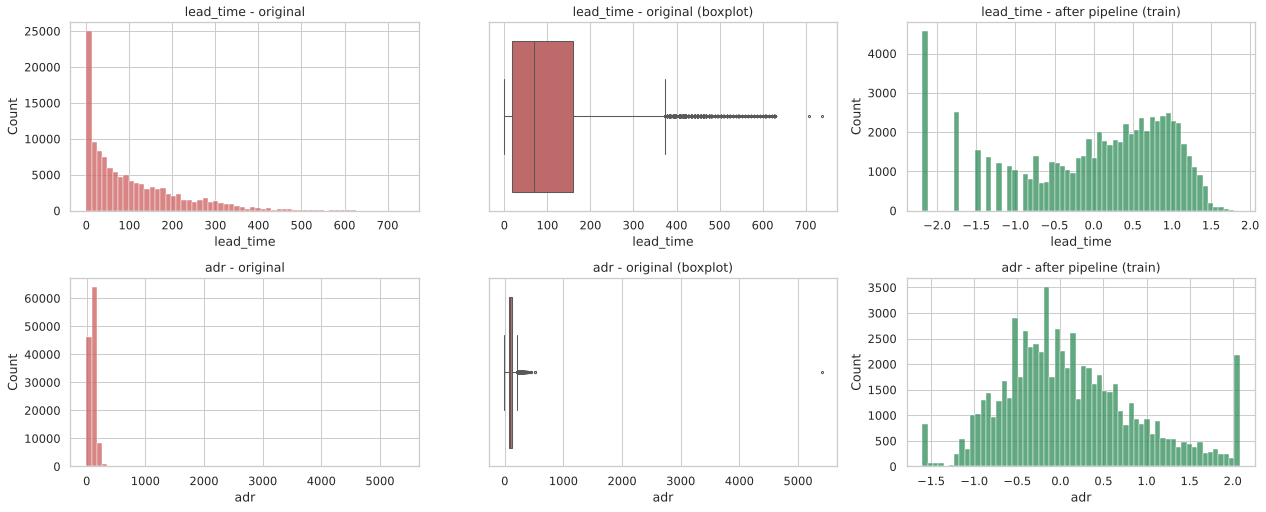

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7))
for i, c in enumerate(["lead_time", "adr"]):
    sns.histplot(df_raw[c], bins=60, ax=axes[i, 0], color="indianred");       axes[i, 0].set_title(f"{c} - original")
    sns.boxplot(x=df_raw[c], ax=axes[i, 1], color="indianred", fliersize=2);  axes[i, 1].set_title(f"{c} - original (boxplot)")
    sns.histplot(X_train_proc[c], bins=60, ax=axes[i, 2], color="seagreen");  axes[i, 2].set_title(f"{c} - after pipeline (train)")
plt.tight_layout(); plt.show()

In [ ]:
# Outlier percentage before vs after (IQR rule on the first three outlier-prone variables)
rows = []
for c in ["lead_time", "adr"]:
    b = df_raw[c]; a = X_train_proc[c]
    ob = ((b < iqr_bounds(b)[3]) | (b > iqr_bounds(b)[4])).mean() * 100
    oa = ((a < iqr_bounds(a)[3]) | (a > iqr_bounds(a)[4])).mean() * 100
    rows.append([c, ob, oa, b.max(), a.max()])
display(pd.DataFrame(rows, columns=["feature", "% outliers before", "% outliers after", "max before", "max after (scaled)"]).set_index("feature"))

,% outliers before,% outliers after,max before,max after (scaled)
feature,,,,
lead_time,2.517,0.000,737.000,1.864
adr,3.177,0.000,"5,400.000",2.080


**Conclusion:** Compared with the raw data, the final dataset has no missing values, no duplicates, no impossible values, far lower skewness and far fewer outliers, all features are numeric and on comparable scales, and every statistic was learned from training data only – the data are machine-learning-ready.

---
# Final Dataset Preparation and Submission
Besides the encoded/scaled train and test files, we export one **human-readable cleaned dataset** (`hotel_bookings_cleaned.csv`): selected features + target, with duplicates/invalid rows removed, inconsistent labels fixed, remaining missing values filled by mode and continuous outliers capped with IQR fences. (Statistics here come from the whole dataset because this file is a cleaned *copy of the data*; for model training use the leakage-free pipeline outputs above.)

In [ ]:
df_clean = df_model[selected_features + [TARGET]].copy()

# remaining missing values -> mode
for c in ["children", "country", "market_segment", "distribution_channel"]:
    df_clean[c] = df_clean[c].fillna(df_clean[c].mode()[0])
df_clean["children"] = df_clean["children"].astype(int)
df_clean["total_guests"] = (df_clean["adults"] + df_clean["children"] + df_clean["babies"]).astype(int)
df_clean["adr_per_person"] = df_clean["adr"] / df_clean["total_guests"]

# IQR capping of the continuous long-tailed columns
for c in ["lead_time", "adr", "adr_per_person", "total_nights", "stays_in_weekend_nights", "stays_in_week_nights"]:
    if c in df_clean.columns:
        lo, hi = iqr_bounds(df_clean[c])[3:]
        df_clean[c] = df_clean[c].clip(lo, hi)

df_clean.to_csv("hotel_bookings_cleaned.csv", index=False)
print("Cleaned dataset shape:", df_clean.shape)
print("Missing values:", int(df_clean.isna().sum().sum()), "| rows identical on the selected features:", int(df_clean.duplicated().sum()),
      "| leakage columns present:", [c for c in LEAKAGE_COLS if c in df_clean.columns])
display(df_clean.head())
display(df_clean.describe().T)

Cleaned dataset shape: (86617, 39)
Missing values: 0 | rows identical on the selected features: 1501 | leakage columns present: []


,lead_time,arrival_date_year,arrival_date_day_of_month,arrival_quarter,arrival_weekday,arrival_is_weekend,booking_month,booking_weekday,stays_in_weekend_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,adr,has_agent,has_company,total_nights,total_guests,weekend_night_ratio,has_previous_cancellations,has_special_requests,has_parking,adr_per_person,is_domestic,hotel,meal,lead_time_category,market_segment,distribution_channel,deposit_type,customer_type,reserved_room_type,country,agent,arrival_season,is_canceled
0,7.000,2015,1,3,2,0,6,2,0,1,0,0,0,0,0,0,75.000,0,0,1.000,1,0.000,0,0,0,75.000,0,Resort Hotel,BB,Last-minute,Direct,Direct,No Deposit,Transient,A,GBR,No_Agent,Summer,0
1,13.000,2015,1,3,2,0,6,3,0,1,0,0,0,0,0,0,75.000,1,0,1.000,1,0.000,0,0,0,75.000,0,Resort Hotel,BB,Short,Corporate,Corporate,No Deposit,Transient,A,GBR,304,Summer,0
2,14.000,2015,1,3,2,0,6,2,0,2,0,0,0,0,0,0,98.000,1,0,2.000,2,0.000,0,1,0,49.000,0,Resort Hotel,BB,Short,Online TA,TA/TO,No Deposit,Transient,A,GBR,240,Summer,0
3,0.000,2015,1,3,2,0,7,2,0,2,0,0,0,0,0,0,107.000,0,0,2.000,2,0.000,0,0,0,53.500,1,Resort Hotel,BB,Last-minute,Direct,Direct,No Deposit,Transient,C,PRT,No_Agent,Summer,0
4,9.000,2015,1,3,2,0,6,0,0,2,0,0,0,0,0,0,103.000,1,0,2.000,2,0.000,0,1,0,51.500,1,Resort Hotel,FB,Short,Direct,Direct,No Deposit,Transient,C,PRT,303,Summer,0


,count,mean,std,min,25%,50%,75%,max
lead_time,"86,617.000",78.693,80.929,0.000,12.000,50.000,125.000,294.500
arrival_date_year,"86,617.000","2,016.212",0.686,"2,015.000","2,016.000","2,016.000","2,017.000","2,017.000"
arrival_date_day_of_month,"86,617.000",15.819,8.836,1.000,8.000,16.000,23.000,31.000
arrival_quarter,"86,617.000",2.500,1.028,1.000,2.000,3.000,3.000,4.000
arrival_weekday,"86,617.000",2.983,2.008,0.000,1.000,3.000,5.000,6.000
arrival_is_weekend,"86,617.000",0.282,0.450,0.000,0.000,0.000,1.000,1.000
booking_month,"86,617.000",5.739,3.629,1.000,2.000,5.000,9.000,12.000
booking_weekday,"86,617.000",2.598,1.912,0.000,1.000,2.000,4.000,6.000
stays_in_weekend_nights,"86,617.000",1.006,0.993,0.000,0.000,1.000,2.000,5.000
adults,"86,617.000",1.876,0.505,0.000,2.000,2.000,2.000,6.000
